---
embed-resources: True
format:
    html:
        page-layout: full
        fontsize: 18px

title: 'Planificación de capacidad bajo incertidumbre'
subtitle: 'Reoptimización, compra de capacidad y compromiso robusto — DataCare'
author: '[AUTOR — COMPLETAR]'
warning: False
toc: False
---


# Planificación de capacidad bajo incertidumbre
**Reoptimización, compra de capacidad y compromiso robusto — DataCare**

DataCare elige paquetes trimestrales **A** (automatización), **P** (analítica predictiva) y **D** (despliegue dedicado) con impactos de **72**, **95** y **120 puntos**.

| Paquete | Impacto | Ing | Esp | Plataforma | Máximo |
|---------|---------|-----|-----|------------|--------|
| Automatización (A) | 72 | 3 | 1 | 2 | 30 |
| Analítica predictiva (P) | 95 | 2 | 3 | 1 | 25 |
| Despliegue dedicado (D) | 120 | 4 | 2 | 3 | 20 |

**Capacidades base:** ingeniería 120 · especialistas 80 · plataforma 100

$$\max\; 72A + 95P + 120D \quad \text{sujeto a restricciones de recursos y demanda.}$$


In [1]:
# =============================================================================
# Configuración canónica, paleta semántica, solvers y validaciones
# =============================================================================
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from ortools.linear_solver import pywraplp

# --- constantes canónicas ---
C_A, C_P, C_D = 72.0, 95.0, 120.0
A_MAX, P_MAX, D_MAX = 30, 25, 20
ING_BASE, ESP_BASE, PLAT_BASE = 120, 80, 100
E_MAX, S_MAX = 20, 15
COSTO_E_BASE, COSTO_S_BASE = 12, 16
TOL = 1e-6

ESCENARIOS_E1 = [
    ("Base (120,80,100)", 120, 80, 100),
    ("+10 Ingeniería (130,80,100)", 130, 80, 100),
    ("+10 Especialistas (120,90,100)", 120, 90, 100),
    ("+10 Plataforma (120,80,110)", 120, 80, 110),
    ("+10 Ing +10 Esp (130,90,100)", 130, 90, 100),
    ("Ampliado (140,100,120)", 140, 100, 120),
]

ESCENARIOS_E3 = {
    "S1 (120,80,100)": {"ing_cap": 120, "esp_cap": 80, "plat_cap": 100},
    "S2 (110,90,95)": {"ing_cap": 110, "esp_cap": 90, "plat_cap": 95},
    "S3 (130,70,105)": {"ing_cap": 130, "esp_cap": 70, "plat_cap": 105},
}

REPORT_ASSETS = Path("report_assets")
REPORT_ASSETS.mkdir(exist_ok=True)

# --- paleta semántica (sin reutilizar significados) ---
COL_RECURSO = {"Ingeniería": "#2C5F8A", "Especialistas": "#C44E3A", "Plataforma": "#9A9A9A"}
COL_PAQUETE = {"A": "#4C78A8", "P": "#F58518", "D": "#54A24B"}
COL_DECISION = {
    "neutral": "#333333",
    "contexto": "#B0B0B0",
    "positivo": "#2A9D8F",
    "negativo": "#E45756",
    "robusto": "#333333",
    "referencia": "#4C78A8",
    "base": "#6C757D",
}

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica", "Liberation Sans"],
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "legend.frameon": False,
})


def apply_style(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(COL_DECISION["contexto"])
    ax.spines["bottom"].set_color(COL_DECISION["contexto"])
    ax.tick_params(length=0, colors=COL_DECISION["contexto"])
    if grid:
        ax.grid(True, axis=grid, color="#EEEEEE", linewidth=0.8)
        ax.set_axisbelow(True)


def export_fig(fig, name: str):
    fig.savefig(REPORT_ASSETS / f"{name}.png", dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(REPORT_ASSETS / f"{name}.svg", bbox_inches="tight", facecolor="white")


def fmt_plan(a, p, d) -> str:
    return f"({a:.2f}, {p:.2f}, {d:.2f})"


@dataclass
class ResultadoLP:
    status: str
    A: float
    P: float
    D: float
    objetivo: float
    ing_cap: float
    esp_cap: float
    plat_cap: float
    uso_ing: float
    uso_esp: float
    uso_pla: float
    holgura_ing: float
    holgura_esp: float
    holgura_pla: float
    holgura_A: float
    holgura_P: float
    holgura_D: float
    precio_ing: float
    precio_esp: float
    precio_pla: float

    def objetivo_reconstruido(self) -> float:
        return C_A * self.A + C_P * self.P + C_D * self.D

    def restricciones_activas(self, tol: float = 1e-4) -> List[str]:
        activas = []
        if abs(self.holgura_ing) <= tol: activas.append("Ingeniería")
        if abs(self.holgura_esp) <= tol: activas.append("Especialistas")
        if abs(self.holgura_pla) <= tol: activas.append("Plataforma")
        if abs(self.holgura_A) <= tol: activas.append("Demanda A")
        if abs(self.holgura_P) <= tol: activas.append("Demanda P")
        if abs(self.holgura_D) <= tol: activas.append("Demanda D")
        return activas


def resolver_lp(ing_cap=ING_BASE, esp_cap=ESP_BASE, plat_cap=PLAT_BASE, verbose=False) -> Optional[ResultadoLP]:
    solver = pywraplp.Solver.CreateSolver("GLOP")
    assert solver is not None
    A = solver.NumVar(0, A_MAX, "A")
    P = solver.NumVar(0, P_MAX, "P")
    D = solver.NumVar(0, D_MAX, "D")
    c_ing = solver.Add(3 * A + 2 * P + 4 * D <= ing_cap, "ing")
    c_esp = solver.Add(1 * A + 3 * P + 2 * D <= esp_cap, "esp")
    c_pla = solver.Add(2 * A + 1 * P + 3 * D <= plat_cap, "plat")
    solver.Maximize(C_A * A + C_P * P + C_D * D)
    status_code = solver.Solve()
    if status_code != pywraplp.Solver.OPTIMAL:
        return None
    a, p, d = A.solution_value(), P.solution_value(), D.solution_value()
    uso_ing = 3 * a + 2 * p + 4 * d
    uso_esp = 1 * a + 3 * p + 2 * d
    uso_pla = 2 * a + 1 * p + 3 * d
    return ResultadoLP(
        status="OPTIMAL", A=a, P=p, D=d, objetivo=solver.Objective().Value(),
        ing_cap=ing_cap, esp_cap=esp_cap, plat_cap=plat_cap,
        uso_ing=uso_ing, uso_esp=uso_esp, uso_pla=uso_pla,
        holgura_ing=ing_cap - uso_ing, holgura_esp=esp_cap - uso_esp, holgura_pla=plat_cap - uso_pla,
        holgura_A=A_MAX - a, holgura_P=P_MAX - p, holgura_D=D_MAX - d,
        precio_ing=c_ing.dual_value(), precio_esp=c_esp.dual_value(), precio_pla=c_pla.dual_value(),
    )


def validar_lp(res: ResultadoLP, tol=TOL) -> Dict:
    checks = {
        "status_optimo": res.status == "OPTIMAL",
        "objetivo_ok": abs(res.objetivo_reconstruido() - res.objetivo) <= tol,
        "factible_ing": res.uso_ing <= res.ing_cap + tol,
        "factible_esp": res.uso_esp <= res.esp_cap + tol,
        "factible_pla": res.uso_pla <= res.plat_cap + tol,
        "demanda_A": res.A <= A_MAX + tol,
        "demanda_P": res.P <= P_MAX + tol,
        "demanda_D": res.D <= D_MAX + tol,
    }
    checks["ok"] = all(checks.values())
    return checks


def fila_escenario(res: ResultadoLP, escenario: str, z_base: float) -> Dict:
    delta = res.objetivo - z_base
    return {
        "Escenario": escenario,
        "Cap. Ing": res.ing_cap, "Cap. Esp": res.esp_cap, "Cap. Plat": res.plat_cap,
        "Plan (A,P,D)": fmt_plan(res.A, res.P, res.D),
        "A": res.A, "P": res.P, "D": res.D,
        "Objetivo": res.objetivo,
        "Δ vs base": delta,
        "% Δ": 100 * delta / z_base,
        "Uso Ing": res.uso_ing, "Uso Esp": res.uso_esp, "Uso Plat": res.uso_pla,
        "Holg. Ing": res.holgura_ing, "Holg. Esp": res.holgura_esp, "Holg. Plat": res.holgura_pla,
        "Restricciones activas": ", ".join(res.restricciones_activas()) or "—",
    }


def test_monotonicidad(resultados: Dict[str, ResultadoLP]) -> pd.DataFrame:
    """Prueba todos los pares con capacidades componente a componente >=."""
    nombres = list(resultados.keys())
    filas = []
    for i, ni in enumerate(nombres):
        ri = resultados[ni]
        bi = (ri.ing_cap, ri.esp_cap, ri.plat_cap)
        for j, nj in enumerate(nombres):
            if i == j:
                continue
            rj = resultados[nj]
            bj = (rj.ing_cap, rj.esp_cap, rj.plat_cap)
            if all(bj[k] >= bi[k] - TOL for k in range(3)):
                ok = rj.objetivo >= ri.objetivo - TOL
                filas.append({"Desde": ni, "Hacia": nj, "Δz": rj.objetivo - ri.objetivo, "OK": ok})
                assert ok, f"Monotonicidad violada: {ni} -> {nj}"
    return pd.DataFrame(filas)


### Contexto del taller y FMA global

Este cuaderno documenta tres ejercicios del taller DataCare (C04E1–C04E3). Cada ejercicio incluye su **formulación primal**, **supuestos**, **FMA específica** e implementación validada.

La FMA detallada de cada ejercicio aparece antes de su sección computacional. Esta tabla resume el contexto común.

| Campo | Contenido |
|-------|-----------|
| **Decisor** | Directora de Entrega, DataCare |
| **Horizonte** | Un trimestre |
| **Unidades** | Paquetes continuos; capacidad en unidades de recurso; impacto en puntos |
| **Solver** | OR-Tools GLOP (LP continuo) |
| **Tolerancia numérica** | $10^{-6}$ |
| **Firma global** | [COMPLETAR POR EL EQUIPO] |


# Análisis principal

## 1. Modelo base y cuellos de botella

¿Qué limita actualmente el plan óptimo? Se resuelve el LP base y se auditan holguras, utilización y precios sombra **locales**.


### Formulación matemática — Modelo base (C04E0)

**Variables de decisión** (continuas):

$$A,\; P,\; D \ge 0$$

- $A$: paquetes de automatización
- $P$: paquetes de analítica predictiva
- $D$: paquetes de despliegue dedicado

**Función objetivo:**

$$\max Z = 72A + 95P + 120D$$

**Restricciones de recursos** (capacidades base $b=(120,\,80,\,100)$):

$$3A + 2P + 4D \le b_I \qquad \text{(Ingeniería)}$$

$$A + 3P + 2D \le b_E \qquad \text{(Especialistas)}$$

$$2A + P + 3D \le b_P \qquad \text{(Plataforma)}$$

**Límites de demanda:**

$$0 \le A \le 30,\qquad 0 \le P \le 25,\qquad 0 \le D \le 20$$


**Tabla de paquetes**

,Paquete,Impacto,Ing,Esp,Plataforma,Máximo
0,Automatización (A),72.0,3,1,2,30
1,Analítica predictiva (P),95.0,2,3,1,25
2,Despliegue dedicado (D),120.0,4,2,3,20


**Plan óptimo base:** (5.71, 11.43, 20.00) · Objetivo = **3,897.14** pts

**Utilización de recursos**

,Recurso,Capacidad,Uso,Holgura,Utilización %
0,Ingeniería,120,120.00,0.00,100.00
1,Especialistas,80,80.00,0.00,100.00
2,Plataforma,100,82.86,17.14,82.86


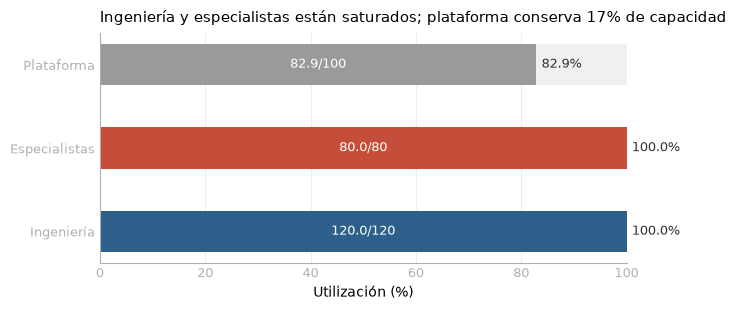

**Insight.** Ingeniería y especialistas están completamente utilizados; plataforma conserva ~17 unidades (~17%). Despliegue dedicado (D) alcanza su límite de demanda (20). Precios sombra locales: ingeniería ≈ 17,29 · especialistas ≈ 20,14 · plataforma = 0.

In [2]:
res_base = resolver_lp(verbose=True)
assert res_base is not None
val_base = validar_lp(res_base)
assert val_base["ok"], val_base

# Tablas compactas para informe
tabla_paquetes = pd.DataFrame([
    {"Paquete": "Automatización (A)", "Impacto": C_A, "Ing": 3, "Esp": 1, "Plataforma": 2, "Máximo": A_MAX},
    {"Paquete": "Analítica predictiva (P)", "Impacto": C_P, "Ing": 2, "Esp": 3, "Plataforma": 1, "Máximo": P_MAX},
    {"Paquete": "Despliegue dedicado (D)", "Impacto": C_D, "Ing": 4, "Esp": 2, "Plataforma": 3, "Máximo": D_MAX},
])

tabla_util = pd.DataFrame([
    {"Recurso": "Ingeniería", "Capacidad": res_base.ing_cap, "Uso": res_base.uso_ing,
     "Holgura": res_base.holgura_ing, "Utilización %": 100 * res_base.uso_ing / res_base.ing_cap},
    {"Recurso": "Especialistas", "Capacidad": res_base.esp_cap, "Uso": res_base.uso_esp,
     "Holgura": res_base.holgura_esp, "Utilización %": 100 * res_base.uso_esp / res_base.esp_cap},
    {"Recurso": "Plataforma", "Capacidad": res_base.plat_cap, "Uso": res_base.uso_pla,
     "Holgura": res_base.holgura_pla, "Utilización %": 100 * res_base.uso_pla / res_base.plat_cap},
])

display(Markdown("**Tabla de paquetes**"))
display(tabla_paquetes.round(2))
display(Markdown(f"**Plan óptimo base:** {fmt_plan(res_base.A, res_base.P, res_base.D)} · Objetivo = **{res_base.objetivo:,.2f}** pts"))
display(Markdown("**Utilización de recursos**"))
display(tabla_util.round(2))

# Figura exploratoria: utilización horizontal 0–100%
fig, ax = plt.subplots(figsize=(7, 3.2))
recursos = ["Ingeniería", "Especialistas", "Plataforma"]
utils = [100 * res_base.uso_ing / res_base.ing_cap,
         100 * res_base.uso_esp / res_base.esp_cap,
         100 * res_base.uso_pla / res_base.plat_cap]
y = np.arange(len(recursos))
for i, (r, u, row) in enumerate(zip(recursos, utils, tabla_util.itertuples())):
    ax.barh(i, u, color=COL_RECURSO[r], height=0.5, label=r)
    ax.barh(i, 100 - u, left=u, color="#F0F0F0", height=0.5)
    ax.text(u / 2, i, f"{row.Uso:.1f}/{row.Capacidad:.0f}", ha="center", va="center", fontsize=9, color="white")
    ax.text(u + 1, i, f"{u:.1f}%", va="center", fontsize=9, color=COL_DECISION["neutral"])
ax.set_xlim(0, 100)
ax.set_yticks(y)
ax.set_yticklabels(recursos)
ax.set_xlabel("Utilización (%)")
ax.set_title("Ingeniería y especialistas están saturados; plataforma conserva 17% de capacidad", loc="left", pad=8)
apply_style(ax, grid="x")
fig.tight_layout()
plt.show()

display(Markdown(
    "**Insight.** Ingeniería y especialistas están completamente utilizados; plataforma conserva ~17 unidades (~17%). "
    "Despliegue dedicado (D) alcanza su límite de demanda (20). "
    "Precios sombra locales: ingeniería ≈ 17,29 · especialistas ≈ 20,14 · plataforma = 0."
))


## 2. Ejercicio 1 — Reoptimización exacta por escenarios

Seis vectores de capacidad resueltos de forma independiente. El DataFrame canónico es la fuente de verdad.


### Formulación matemática — Ejercicio 1 (C04E1)

**Variables de decisión** (continuas):

$$A,\; P,\; D \ge 0$$

**Función objetivo:**

$$\max Z = 72A + 95P + 120D$$

**Restricciones de recursos** para un vector genérico de capacidad $b=(b_I, b_E, b_P)$:

$$3A + 2P + 4D \le b_I$$

$$A + 3P + 2D \le b_E$$

$$2A + P + 3D \le b_P$$

**Límites de demanda:**

$$A \le 30,\qquad P \le 25,\qquad D \le 20$$

> Cada vector de capacidad reemplaza únicamente los lados derechos correspondientes. El mismo modelo de optimización se resuelve **de nuevo desde cero** en cada escenario.

> Los seis vectores alternativos representan **escenarios trimestrales independientes**; las capacidades **no son acumulativas**.


### Supuestos y exclusiones — Ejercicio 1

- Los paquetes son **divisibles** porque representan volúmenes agregados de trabajo.
- El aporte por paquete es **constante** dentro del trimestre.
- El consumo de recursos por paquete es **constante** dentro del trimestre.
- Los límites de demanda **no cambian** entre escenarios de capacidad.
- Cada escenario se conoce **antes** de seleccionar el plan óptimo correspondiente.
- Los puntos de impacto son **comparables** entre $A$, $P$ y $D$.
- Los seis vectores son **escenarios alternativos**, no adiciones acumulativas.
- Las conclusiones sobre interacción aplican **solo** a los vectores evaluados.

**Conexión con el residual observado:**

$$\Delta_{I,E} - (\Delta_I + \Delta_E) \approx 0$$

para la ampliación evaluada de +10 unidades de ingeniería y +10 de especialistas. Esto indica aditividad **dentro de la tolerancia numérica** en esa combinación; **no** debe extrapolarse como propiedad universal fuera de la región evaluada.


### FMA — Ejercicio 1 (C04E1)

| Campo | Contenido |
|-------|-----------|
| **Decisor, horizonte y acción controlable** | Directora de Entrega elige el mix $(A,P,D)$ para un trimestre, dado un vector de capacidad conocido antes de decidir. |
| **Datos, índices, fuente y unidades** | Coeficientes de impacto (72, 95, 120); consumos por recurso; capacidades $b$; demandas máximas; unidades de impacto en puntos. |
| **Variables, significado, dominio y unidad** | $A,P,D \ge 0$ continuas; topes 30, 25, 20. |
| **Objetivo y convención de signo** | Maximizar impacto trimestral $Z=72A+95P+120D$. |
| **Restricciones con nombre e interpretación** | Ing: consumo de ingeniería; Esp: consumo de especialistas; Plat: consumo de plataforma; Demanda: topes comerciales por paquete. |
| **Supuestos y exclusiones** | Ver sección anterior; sin probabilidades; sin compra endógena de capacidad. |
| **Dos casos manuales / controles** | **Control 1:** $b=(120,80,100)$ → óptimo validado $(A,P,D)\approx(5.71,11.43,20)$, $Z\approx3897.14$. **Control 2:** $b=(120,80,110)$ → la solución base sigue factible; $Z$ no disminuye; en la solución computada $Z$ permanece igual porque plataforma era no activa. |
| **Métricas, tolerancias y controles** | Reconstrucción de $Z$; factibilidad de recursos y demandas; monotonicidad componente a componente; residual de interacción. Tolerancia $10^{-6}$. |
| **Firma del modelador y auditor** | [COMPLETAR POR EL EQUIPO] |


**Tabla de decisión — seis escenarios**

,Escenario,"Plan (A,P,D)",Objetivo,Δ vs base,% Δ,Restricciones activas
0,"Base (120,80,100)","(5.71, 11.43, 20.00)",3897.14,0.00,0.00,"Ingeniería, Especialistas, Demanda D"
1,"+10 Ingeniería (130,80,100)","(10.00, 10.00, 20.00)",4070.00,172.86,4.44,"Ingeniería, Especialistas, Demanda D"
2,"+10 Especialistas (120,90,100)","(2.86, 15.71, 20.00)",4098.57,201.43,5.17,"Ingeniería, Especialistas, Demanda D"
3,"+10 Plataforma (120,80,110)","(5.71, 11.43, 20.00)",3897.14,0.00,0.00,"Ingeniería, Especialistas, Demanda D"
4,"+10 Ing +10 Esp (130,90,100)","(7.14, 14.29, 20.00)",4271.43,374.29,9.60,"Ingeniería, Especialistas, Demanda D"
5,"Ampliado (140,100,120)","(8.57, 17.14, 20.00)",4645.71,748.57,19.21,"Ingeniería, Especialistas, Demanda D"


**Tabla de restricciones**

,Escenario,Holg. Ing,Holg. Esp,Holg. Plat,Restricciones activas
0,"Base (120,80,100)",0.0,0.0,17.14,"Ingeniería, Especialistas, Demanda D"
1,"+10 Ingeniería (130,80,100)",0.0,0.0,10.00,"Ingeniería, Especialistas, Demanda D"
2,"+10 Especialistas (120,90,100)",0.0,0.0,18.57,"Ingeniería, Especialistas, Demanda D"
3,"+10 Plataforma (120,80,110)",0.0,0.0,27.14,"Ingeniería, Especialistas, Demanda D"
4,"+10 Ing +10 Esp (130,90,100)",0.0,0.0,11.43,"Ingeniería, Especialistas, Demanda D"
5,"Ampliado (140,100,120)",0.0,0.0,25.71,"Ingeniería, Especialistas, Demanda D"


**Test de monotonicidad:** 11 pares válidos — todos OK

**Interacción entre ampliaciones evaluadas**

,Ampliación,Δ objetivo (pts)
0,+10 Ingeniería,172.86
1,+10 Especialistas,201.43
2,+10 Plataforma,0.00
3,+10 Ing +10 Esp,374.29
4,Interacción (residual),0.00


Para la ampliación evaluada de +10 unidades de ingeniería y +10 de especialistas, los beneficios son **aditivos dentro de la tolerancia numérica** (residual = 0.0000 pts). Esto **no** demuestra aditividad global fuera de la región evaluada; la sensibilidad continua puede mostrar cambios de régimen en otros niveles de capacidad.

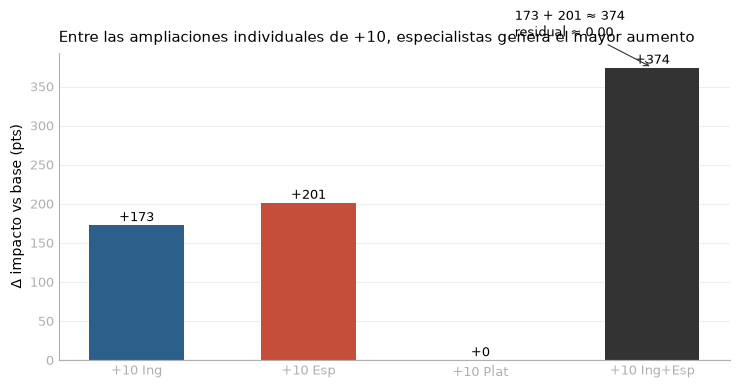

**Escenario ampliado (140,100,120):** objetivo = 4,645.71 pts (Δ = +748.57). Se reporta en tabla, no en la figura principal.

In [3]:
z_base = res_base.objetivo
resultados_e1 = {}
filas_e1 = []
for nombre, ing, esp, plat in ESCENARIOS_E1:
    r = resolver_lp(ing, esp, plat)
    assert r is not None, nombre
    assert validar_lp(r)["ok"], nombre
    resultados_e1[nombre] = r
    filas_e1.append(fila_escenario(r, nombre, z_base))

df_escenarios = pd.DataFrame(filas_e1)
df_escenarios_analitico = df_escenarios.copy()  # wide internal

# Tablas compactas para informe
df_esc_decision = df_escenarios[["Escenario", "Plan (A,P,D)", "Objetivo", "Δ vs base", "% Δ", "Restricciones activas"]].copy()
df_esc_restr = df_escenarios[["Escenario", "Holg. Ing", "Holg. Esp", "Holg. Plat", "Restricciones activas"]].copy()

display(Markdown("**Tabla de decisión — seis escenarios**"))
display(df_esc_decision.round(2))
display(Markdown("**Tabla de restricciones**"))
display(df_esc_restr.round(2))

# Monotonicidad: todos los pares válidos
df_mono = test_monotonicidad(resultados_e1)
display(Markdown(f"**Test de monotonicidad:** {len(df_mono)} pares válidos — todos OK"))

# Interacción +10/+10
z0 = resultados_e1["Base (120,80,100)"].objetivo
zI = resultados_e1["+10 Ingeniería (130,80,100)"].objetivo
zE = resultados_e1["+10 Especialistas (120,90,100)"].objetivo
zP = resultados_e1["+10 Plataforma (120,80,110)"].objetivo
zIE = resultados_e1["+10 Ing +10 Esp (130,90,100)"].objetivo
zAmp = resultados_e1["Ampliado (140,100,120)"].objetivo

delta_I, delta_E, delta_P, delta_IE = zI - z0, zE - z0, zP - z0, zIE - z0
interaccion = delta_IE - (delta_I + delta_E)

tabla_inter = pd.DataFrame([
    {"Ampliación": "+10 Ingeniería", "Δ objetivo (pts)": delta_I},
    {"Ampliación": "+10 Especialistas", "Δ objetivo (pts)": delta_E},
    {"Ampliación": "+10 Plataforma", "Δ objetivo (pts)": delta_P},
    {"Ampliación": "+10 Ing +10 Esp", "Δ objetivo (pts)": delta_IE},
    {"Ampliación": "Interacción (residual)", "Δ objetivo (pts)": interaccion},
])
display(Markdown("**Interacción entre ampliaciones evaluadas**"))
display(tabla_inter.round(2))

if abs(interaccion) <= 0.01:
    display(Markdown(
        "Para la ampliación evaluada de +10 unidades de ingeniería y +10 de especialistas, "
        "los beneficios son **aditivos dentro de la tolerancia numérica** "
        f"(residual = {interaccion:.4f} pts). "
        "Esto **no** demuestra aditividad global fuera de la región evaluada; "
        "la sensibilidad continua puede mostrar cambios de régimen en otros niveles de capacidad."
    ))

# Figura principal: solo comparaciones +10 (sin escenario ampliado)
fig, ax = plt.subplots(figsize=(7.5, 4))
labels = ["+10 Ing", "+10 Esp", "+10 Plat", "+10 Ing+Esp"]
deltas = [delta_I, delta_E, delta_P, delta_IE]
cols = [COL_RECURSO["Ingeniería"], COL_RECURSO["Especialistas"], COL_RECURSO["Plataforma"], COL_DECISION["neutral"]]
bars = ax.bar(labels, deltas, color=cols, width=0.55)
ax.axhline(0, color=COL_DECISION["contexto"], lw=0.8)
for b, d in zip(bars, deltas):
    ax.text(b.get_x() + b.get_width() / 2, d + 5, f"+{d:.0f}", ha="center", fontsize=9)
ax.annotate(f"{delta_I:.0f} + {delta_E:.0f} ≈ {delta_IE:.0f}\nresidual ≈ {interaccion:.2f}",
            xy=(3, delta_IE), xytext=(2.2, delta_IE + 40), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=COL_DECISION["neutral"], lw=0.8))
ax.set_ylabel("Δ impacto vs base (pts)")
ax.set_title("Entre las ampliaciones individuales de +10, especialistas genera el mayor aumento", loc="left", pad=8)
apply_style(ax)
fig.tight_layout()
plt.show()

display(Markdown(f"**Escenario ampliado (140,100,120):** objetivo = {zAmp:,.2f} pts (Δ = +{zAmp - z0:,.2f}). Se reporta en tabla, no en la figura principal."))


# Análisis suplementario

## Sensibilidad continua de capacidad (0–40%)

Cada recurso se amplía independientemente. Grilla: **81 puntos** (paso ≈ 0,5%). Precios sombra = valores marginales **locales**. Un cambio detectado en el primer paso de la grilla no implica un quiebre analítico exacto.


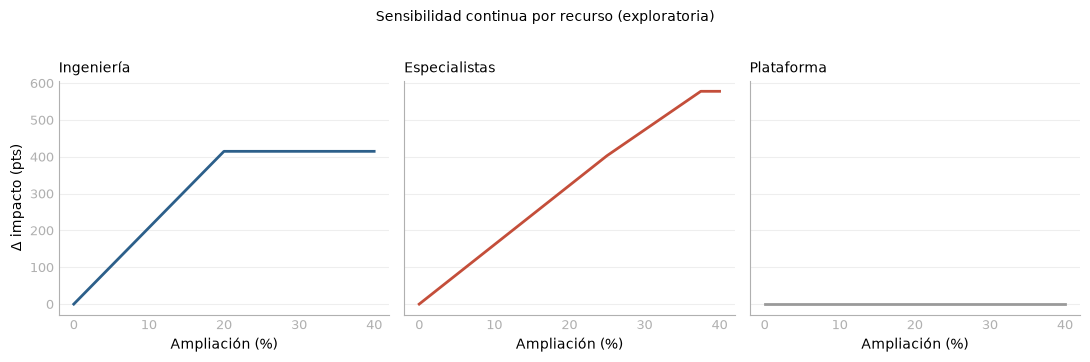

In [4]:
aumentos = np.linspace(0, 0.40, 81)
recursos_params = {
    "Ingeniería": ("ing_cap", ING_BASE),
    "Especialistas": ("esp_cap", ESP_BASE),
    "Plataforma": ("plat_cap", PLAT_BASE),
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
for ax, (nombre, (param, cap0)) in zip(axes, recursos_params.items()):
    deltas_sens = []
    for a in aumentos:
        caps = {"ing_cap": ING_BASE, "esp_cap": ESP_BASE, "plat_cap": PLAT_BASE}
        caps[param] = cap0 * (1 + a)
        r = resolver_lp(**caps)
        deltas_sens.append(r.objetivo - z_base)
    ax.plot(aumentos * 100, deltas_sens, color=COL_RECURSO[nombre], lw=2)
    ax.set_title(nombre, loc="left", fontsize=10)
    ax.set_xlabel("Ampliación (%)")
    if ax is axes[0]:
        ax.set_ylabel("Δ impacto (pts)")
    apply_style(ax)
fig.suptitle("Sensibilidad continua por recurso (exploratoria)", y=1.02, fontsize=10)
fig.tight_layout()
plt.show()


## Sensibilidad de coeficientes de la función objetivo

Rangos analíticos que conservan el vértice $(40/7,\; 80/7,\; 20)$ al variar un coeficiente.


,Coeficiente,Actual,Lím. inf.,Lím. sup.
0,Aporte A,72.0,31.67,81.25
1,Aporte P,95.0,48.00,132.0
2,Aporte D,120.0,109.43,∞


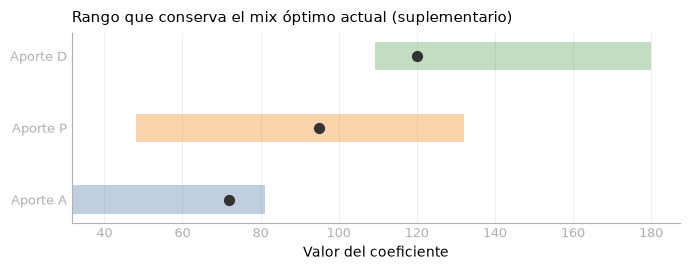

In [5]:
def rango_coef(var):
    if var == "A":
        return C_P / 3, min(3 * C_P / 2, (7 * C_D - 2 * C_P) / 8)
    if var == "P":
        return 2 * C_A / 3, min(3 * C_A, (7 * C_D - 8 * C_A) / 2)
    return (8 * C_A + 2 * C_P) / 7, float("inf")

df_rangos = pd.DataFrame([
    {"Coeficiente": "Aporte A", "Actual": C_A, "Lím. inf.": rango_coef("A")[0],
     "Lím. sup.": rango_coef("A")[1]},
    {"Coeficiente": "Aporte P", "Actual": C_P, "Lím. inf.": rango_coef("P")[0],
     "Lím. sup.": rango_coef("P")[1]},
    {"Coeficiente": "Aporte D", "Actual": C_D, "Lím. inf.": rango_coef("D")[0],
     "Lím. sup.": "∞"},
])
display(df_rangos.round(2))

fig, ax = plt.subplots(figsize=(7, 2.8))
keys = ["A", "P", "D"]
for i, key in enumerate(keys):
    lo_val = df_rangos.loc[i, "Lím. inf."]
    hi_raw = df_rangos.loc[i, "Lím. sup."]
    hi_val = 180 if hi_raw == "∞" else hi_raw
    ax.barh(i, hi_val - lo_val, left=lo_val, height=0.4, color=COL_PAQUETE[key], alpha=0.35)
    ax.scatter([df_rangos.loc[i, "Actual"]], [i], color=COL_DECISION["neutral"], s=50, zorder=5)
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Aporte A", "Aporte P", "Aporte D"])
ax.set_xlabel("Valor del coeficiente")
ax.set_title("Rango que conserva el mix óptimo actual (suplementario)", loc="left", pad=8)
apply_style(ax, grid="x")
fig.tight_layout()
plt.show()


## 3. Ejercicio 2 — Compra de capacidad dentro del modelo

¿Conviene comprar capacidad al precio actual? Variables $e \in [0,20]$ (12 pts/u) y $s \in [0,15]$ (16 pts/u).


### Formulación matemática — Ejercicio 2 (C04E2)

**Variables de decisión** (continuas):

$$A,\; P,\; D,\; e,\; s \ge 0$$

con:

$$0 \le e \le 20,\qquad 0 \le s \le 15$$

- $e$: capacidad adicional de ingeniería comprada
- $s$: capacidad adicional de especialistas comprada

**Función objetivo:**

$$\max Z = 72A + 95P + 120D - 12e - 16s$$

**Restricciones:**

$$3A + 2P + 4D \le 120 + e \qquad \text{(Ingeniería)}$$

$$A + 3P + 2D \le 80 + s \qquad \text{(Especialistas)}$$

$$2A + P + 3D \le 100 \qquad \text{(Plataforma — sin compra)}$$

$$A \le 30,\quad P \le 25,\quad D \le 20,\quad e \le 20,\quad s \le 15$$

**Nota sobre el coeficiente $-1$ (lado izquierdo equivalente):**

Si la restricción de ingeniería se escribe $3A+2P+4D \le 120+e$, al pasar la capacidad comprada al lado izquierdo:

$$3A + 2P + 4D - e \le 120$$

Por tanto $e$ tiene coeficiente $-1$. Análogamente: $A+3P+2D-s \le 80$. El signo negativo **no** representa capacidad negativa; indica que comprar una unidad adicional **relaja** la restricción de recurso en una unidad.

**Continuidad de $e$ y $s$:**

$e$ y $s$ son continuas porque el contrato enunciado permite **unidades fraccionarias equivalentes** de capacidad externa.

**Consecuencia de modelado (limitación, no implementación):** si la capacidad real se vendiera solo en bloques discretos, los dominios deberían volverse enteros o mixtos-enteros; si existiera un cargo fijo de activación, haría falta una variable binaria. El modelo actual **no** implementa esas extensiones.


### Supuestos y exclusiones — Ejercicio 2

- La capacidad externa tiene la **misma productividad** que la interna.
- La capacidad comprada se consume en el **mismo trimestre**.
- La capacidad comprada no utilizada **no se acumula** como inventario.
- Los costos de compra son **lineales** (12 pts/u ingeniería; 16 pts/u especialistas).
- **No** hay cargos fijos ni descuentos por volumen.
- La compra de ingeniería y especialistas es **divisible**.
- **No** se puede comprar capacidad de plataforma.
- Aporte y consumo de recursos por paquete permanecen **lineales**.
- Impacto bruto y costos de compra se expresan en la **misma escala** del objetivo.
- Si el contrato real fuera por bloques o incluyera costos fijos, esta formulación LP **dejaría de representar** el contrato (probablemente MILP).


### FMA — Ejercicio 2 (C04E2)

| Campo | Contenido |
|-------|-----------|
| **Decisor, horizonte y acción controlable** | Directora elige simultáneamente mix $(A,P,D)$ y compras $(e,s)$ para maximizar impacto neto trimestral. |
| **Datos, índices, fuente y unidades** | Capacidades base (120, 80, 100); costos unitarios 12 y 16; topes de compra 20 y 15; mismos coeficientes de impacto y consumo que el modelo base. |
| **Variables, significado, dominio y unidad** | $A,P,D,e,s \ge 0$ continuas con topes indicados. |
| **Objetivo y convención de signo** | Maximizar $Z = 72A+95P+120D - 12e - 16s$ (impacto neto). |
| **Restricciones con nombre e interpretación** | Ing ampliada por $e$; Esp ampliada por $s$; Plat fija; demandas; topes de compra. |
| **Supuestos y exclusiones** | Ver sección anterior. |
| **Dos casos manuales / controles** | **Control 1 — sin compra:** $e=s=0$ → reproduce el modelo base y objetivo $\approx 3897.14$. **Control 2 — costo prohibitivo:** costos artificialmente altos → $e=s=0$ y plan idéntico al base (verificado numéricamente). |
| **Métricas, tolerancias y controles** | Reconstrucción de bruto, costo y neto; factibilidad con capacidad comprada; umbrales por reoptimización. Tolerancia $10^{-6}$. |
| **Firma del modelador y auditor** | [COMPLETAR POR EL EQUIPO] |


In [6]:
@dataclass
class ResultadoCompra:
    status: str
    A: float
    P: float
    D: float
    e: float
    s: float
    bruto: float
    costo_ing: float
    costo_esp: float
    costo_total: float
    neto: float
    uso_ing: float
    uso_esp: float
    uso_pla: float
    holgura_ing: float
    holgura_esp: float
    holgura_pla: float
    precio_ing: float
    precio_esp: float
    precio_pla: float


def resolver_compra(costo_e=COSTO_E_BASE, costo_s=COSTO_S_BASE) -> Optional[ResultadoCompra]:
    solver = pywraplp.Solver.CreateSolver("GLOP")
    A = solver.NumVar(0, A_MAX, "A")
    P = solver.NumVar(0, P_MAX, "P")
    D = solver.NumVar(0, D_MAX, "D")
    e = solver.NumVar(0, E_MAX, "e")
    s = solver.NumVar(0, S_MAX, "s")
    c_ing = solver.Add(3 * A + 2 * P + 4 * D <= ING_BASE + e, "ing")
    c_esp = solver.Add(1 * A + 3 * P + 2 * D <= ESP_BASE + s, "esp")
    c_pla = solver.Add(2 * A + 1 * P + 3 * D <= PLAT_BASE, "plat")
    solver.Maximize(C_A * A + C_P * P + C_D * D - costo_e * e - costo_s * s)
    if solver.Solve() != pywraplp.Solver.OPTIMAL:
        return None
    a, p, d = A.solution_value(), P.solution_value(), D.solution_value()
    ev, sv = e.solution_value(), s.solution_value()
    bruto = C_A * a + C_P * p + C_D * d
    ci, cs = costo_e * ev, costo_s * sv
    return ResultadoCompra(
        status="OPTIMAL", A=a, P=p, D=d, e=ev, s=sv,
        bruto=bruto, costo_ing=ci, costo_esp=cs, costo_total=ci + cs,
        neto=bruto - ci - cs,
        uso_ing=3*a+2*p+4*d, uso_esp=1*a+3*p+2*d, uso_pla=2*a+1*p+3*d,
        holgura_ing=ING_BASE+ev-(3*a+2*p+4*d), holgura_esp=ESP_BASE+sv-(1*a+3*p+2*d),
        holgura_pla=PLAT_BASE-(2*a+1*p+3*d),
        precio_ing=c_ing.dual_value(), precio_esp=c_esp.dual_value(), precio_pla=c_pla.dual_value(),
    )


def validar_compra(r: ResultadoCompra, costo_e, costo_s, tol=TOL) -> Dict:
    checks = {
        "status": r.status == "OPTIMAL",
        "bruto_ok": abs(r.bruto - (C_A*r.A + C_P*r.P + C_D*r.D)) <= tol,
        "costo_ok": abs(r.costo_total - (costo_e*r.e + costo_s*r.s)) <= tol,
        "neto_ok": abs(r.neto - (r.bruto - r.costo_total)) <= tol,
        "e_bound": -tol <= r.e <= E_MAX + tol,
        "s_bound": -tol <= r.s <= S_MAX + tol,
        "A_bound": -tol <= r.A <= A_MAX + tol,
        "P_bound": -tol <= r.P <= P_MAX + tol,
        "D_bound": -tol <= r.D <= D_MAX + tol,
        "ing_ok": r.uso_ing <= ING_BASE + r.e + tol,
        "esp_ok": r.uso_esp <= ESP_BASE + r.s + tol,
        "pla_ok": r.uso_pla <= PLAT_BASE + tol,
    }
    checks["ok"] = all(checks.values())
    return checks


res_compra = resolver_compra()
assert res_compra is not None
assert validar_compra(res_compra, COSTO_E_BASE, COSTO_S_BASE)["ok"]

# Sin compra vía costos altos
res_sin = resolver_compra(costo_e=1e6, costo_s=1e6)
assert res_sin.e < TOL and res_sin.s < TOL
assert abs(res_sin.neto - z_base) < 1e-3
assert abs(res_sin.A - res_base.A) < 1e-3

tabla_compra = pd.DataFrame([
    {"Escenario": "Sin compra", "Plan": fmt_plan(res_base.A, res_base.P, res_base.D),
     "e": 0, "s": 0, "Bruto": z_base, "Costo": 0, "Neto": z_base},
    {"Escenario": "Con compra", "Plan": fmt_plan(res_compra.A, res_compra.P, res_compra.D),
     "e": res_compra.e, "s": res_compra.s, "Bruto": res_compra.bruto,
     "Costo": res_compra.costo_total, "Neto": res_compra.neto},
])
display(tabla_compra.round(2))
incremental = res_compra.neto - z_base
display(Markdown(
    f"**Desglose:** bruto +{res_compra.bruto - z_base:.0f} pts · costo −{res_compra.costo_total:.0f} pts "
    f"(Ing {res_compra.costo_ing:.0f} + Esp {res_compra.costo_esp:.0f}) · **neto +{incremental:.2f} pts**"
))


,Escenario,Plan,e,s,Bruto,Costo,Neto
0,Sin compra,"(5.71, 11.43, 20.00)",0.0,0.0,3897.14,0.0,3897.14
1,Con compra,"(10.00, 15.00, 20.00)",20.0,15.0,4545.00,480.0,4065.00


**Desglose:** bruto +648 pts · costo −480 pts (Ing 240 + Esp 240) · **neto +167.86 pts**

**Umbrales numéricos (compra → 0):** ingeniería ≈ **17.29** pts/u · especialistas ≈ **20.14** pts/u. Coinciden con precios sombra locales (17.29 y 20.14) en esta región.

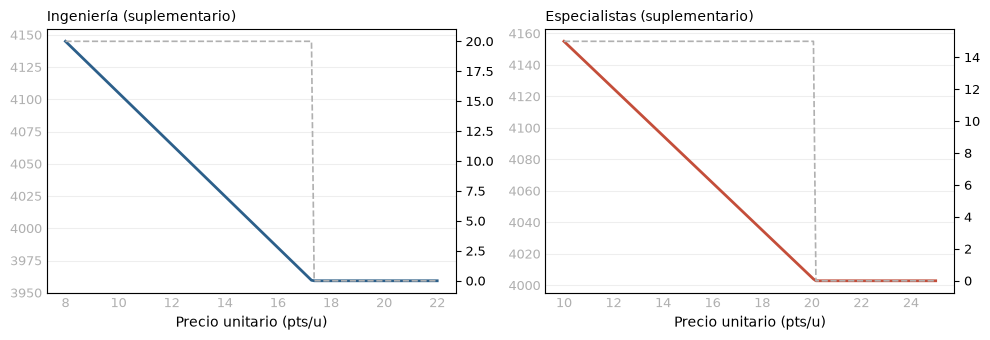

In [7]:
def umbral_compra(param="e", p_min=5, p_max=30, n_grueso=300):
    """Detecta transición compra→0 con búsqueda gruesa + refinamiento binario."""
    precios = np.linspace(p_min, p_max, n_grueso)
    compras = []
    for p in precios:
        r = resolver_compra(costo_e=p, costo_s=COSTO_S_BASE) if param == "e" else resolver_compra(costo_e=COSTO_E_BASE, costo_s=p)
        compras.append(r.e if param == "e" else r.s)
    compras = np.array(compras)
    # último precio con compra > tol
    activos = np.where(compras > 0.01)[0]
    if len(activos) == 0:
        return None, precios, compras
    idx_hi = activos[-1]
    lo_p = precios[idx_hi]
    hi_p = precios[min(idx_hi + 1, len(precios) - 1)]
    # refinamiento binario
    for _ in range(40):
        mid = (lo_p + hi_p) / 2
        r = resolver_compra(costo_e=mid, costo_s=COSTO_S_BASE) if param == "e" else resolver_compra(costo_e=COSTO_E_BASE, costo_s=mid)
        c = r.e if param == "e" else r.s
        if c > 0.01:
            lo_p = mid
        else:
            hi_p = mid
    return (lo_p + hi_p) / 2, precios, compras

umbral_e, _, _ = umbral_compra("e", 8, 22)
umbral_s, _, _ = umbral_compra("s", 10, 25)
display(Markdown(
    f"**Umbrales numéricos (compra → 0):** ingeniería ≈ **{umbral_e:.2f}** pts/u · "
    f"especialistas ≈ **{umbral_s:.2f}** pts/u. "
    f"Coinciden con precios sombra locales ({res_compra.precio_ing:.2f} y {res_compra.precio_esp:.2f}) en esta región."
))

# Figura suplementaria: curvas detalladas
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, param, col, titulo in [
    (axes[0], "e", COL_RECURSO["Ingeniería"], "Ingeniería"),
    (axes[1], "s", COL_RECURSO["Especialistas"], "Especialistas"),
]:
    precios = np.linspace(8, 22, 140) if param == "e" else np.linspace(10, 25, 150)
    netos, compras = [], []
    for p in precios:
        r = resolver_compra(costo_e=p, costo_s=COSTO_S_BASE) if param == "e" else resolver_compra(costo_e=COSTO_E_BASE, costo_s=p)
        netos.append(r.neto)
        compras.append(r.e if param == "e" else r.s)
    ax2 = ax.twinx()
    ax.plot(precios, netos, color=col, lw=2)
    ax2.plot(precios, compras, color=COL_DECISION["contexto"], ls="--", lw=1.2)
    ax.set_title(f"{titulo} (suplementario)", loc="left", fontsize=10)
    ax.set_xlabel("Precio unitario (pts/u)")
    apply_style(ax)
fig.tight_layout()
plt.show()


## 4. Ejercicio 3 — Plan robusto bajo incertidumbre

Un plan único $(A,P,D)$ factible en S1, S2 y S3. Planes adaptados = **Referencia con información perfecta — no implementable hoy**.


### Formulación matemática — Ejercicio 3 (C04E3)

Se selecciona **un único vector común** $(A,P,D)$ **antes** de conocer qué escenario de capacidad ocurre.

**Función objetivo:**

$$\max Z = 72A + 95P + 120D$$

**Límites de demanda:**

$$0 \le A \le 30,\qquad 0 \le P \le 25,\qquad 0 \le D \le 20$$

Para cada escenario $k \in \{S1, S2, S3\}$ con capacidades $(b_I^k, b_E^k, b_P^k)$:

$$3A + 2P + 4D \le b_I^k$$

$$A + 3P + 2D \le b_E^k$$

$$2A + P + 3D \le b_P^k$$

**Vectores de capacidad:**

$$S1 = (120,\,80,\,100),\quad S2 = (110,\,90,\,95),\quad S3 = (130,\,70,\,105)$$

> Las **nueve** restricciones de recursos definen la **intersección** de las tres regiones factibles. Las variables **no cambian** por escenario.

> Los planes optimizados por escenario con información perfecta son **referencias** únicamente; **no** son alternativas operativas bajo la regla de compromiso anticipado.


### Supuestos y exclusiones — Ejercicio 3

- Ocurre **exactamente uno** de los tres escenarios modelados.
- **No** se consideran escenarios fuera de $\{S1,S2,S3\}$.
- El plan se elige **antes** de observar la capacidad realizada.
- $A$, $P$ y $D$ **no pueden modificarse** después de observar la capacidad.
- Coeficientes de aporte y consumo son **idénticos** en todos los escenarios.
- Límites de demanda **idénticos** en todos los escenarios.
- **No** se asignan probabilidades a escenarios.
- **No** se optimiza valor esperado ni promedio de escenarios.
- El modelo robusto maximiza impacto sobre la **intersección** de conjuntos factibles.
- Planes adaptados = **referencia con información perfecta — no implementable hoy**.

**Conexión con restricciones activas del óptimo robusto computado:**

- **S2** aporta la restricción activa de **Ingeniería**.
- **S3** aporta la restricción activa de **Especialistas**.
- **Plataforma** permanece **no activa** en los tres escenarios.
- **S1** no satura ningún recurso con el plan robusto.


### FMA — Ejercicio 3 (C04E3)

| Campo | Contenido |
|-------|-----------|
| **Decisor, horizonte y acción controlable** | Directora compromete hoy un plan único $(A,P,D)$ factible en los tres escenarios posibles del trimestre. |
| **Datos, índices, fuente y unidades** | Tres vectores de capacidad; mismos coeficientes de impacto, consumo y demanda que modelos previos. |
| **Variables, significado, dominio y unidad** | $A,P,D \ge 0$ continuas compartidas; topes 30, 25, 20. |
| **Objetivo y convención de signo** | Maximizar $Z=72A+95P+120D$ sobre la intersección factible. |
| **Restricciones con nombre e interpretación** | Nueve restricciones de recursos (3 escenarios × 3 recursos); demandas comunes. |
| **Supuestos y exclusiones** | Ver sección anterior; sin probabilidades; sin adaptación ex post. |
| **Dos casos manuales / controles** | **Control 1:** $(A,P,D)=(0,0,0)$ debe ser factible en los tres escenarios (verificado). **Control 2:** sustituir el plan robusto computado en las nueve desigualdades → todas factibles; S2-Ing activa; S3-Esp activa; holgura de plataforma positiva en S1, S2 y S3. |
| **Métricas, tolerancias y controles** | Reconstrucción de $Z$; tabla long-format de 9 restricciones; brecha vs referencia perfecta. Tolerancia $10^{-6}$. |
| **Firma del modelador y auditor** | [COMPLETAR POR EL EQUIPO] |


**Plan robusto:** (4.29, 8.57, 20.00) · **3,522.86 pts**

**Validación — 9 restricciones de recursos**

,Escenario,Recurso,Capacidad,Uso,Holgura,Activa
0,S1,Ingeniería,120,110.00,10.00,No
1,S1,Especialistas,80,70.00,10.00,No
2,S1,Plataforma,100,77.14,22.86,No
3,S2,Ingeniería,110,110.00,0.00,Sí
4,S2,Especialistas,90,70.00,20.00,No
5,S2,Plataforma,95,77.14,17.86,No
6,S3,Ingeniería,130,110.00,20.00,No
7,S3,Especialistas,70,70.00,0.00,Sí
8,S3,Plataforma,105,77.14,27.86,No


**Robusto vs referencia con información perfecta**

,Escenario,Capacidades,Plan robusto,Plan adaptado (ref.),Obj. robusto,Obj. adaptado (ref.),Brecha (pts),Brecha (%)
0,S1,"(120,80,100)","(4.29, 8.57, 20.00)","(5.71, 11.43, 20.00)",3522.86,3897.14,374.29,9.60
1,S2,"(110,90,95)","(4.29, 8.57, 20.00)","(0.00, 17.50, 18.75)",3522.86,3912.50,389.64,9.96
2,S3,"(130,70,105)","(4.29, 8.57, 20.00)","(12.86, 5.71, 20.00)",3522.86,3868.57,345.71,8.94


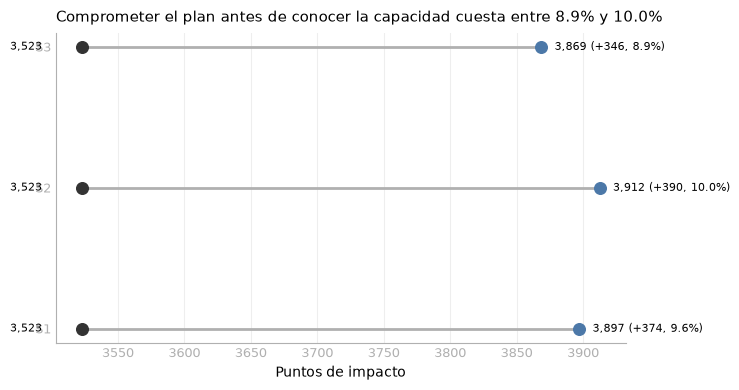

**Callout.** S2 activa ingeniería; S3 activa especialistas. Plataforma no limita el plan robusto. S1 no satura ningún recurso con el plan robusto.

In [8]:
@dataclass
class VerificacionEscenario:
    escenario: str
    recurso: str
    capacidad: float
    uso: float
    holgura: float
    activa: bool


@dataclass
class ResultadoRobusto:
    status: str
    A: float
    P: float
    D: float
    objetivo: float
    holgura_A: float
    holgura_P: float
    holgura_D: float
    verificaciones: List[VerificacionEscenario] = field(default_factory=list)

    def objetivo_reconstruido(self) -> float:
        return C_A * self.A + C_P * self.P + C_D * self.D


def resolver_robusto(escenarios: Dict) -> ResultadoRobusto:
    solver = pywraplp.Solver.CreateSolver("GLOP")
    A = solver.NumVar(0, A_MAX, "A")
    P = solver.NumVar(0, P_MAX, "P")
    D = solver.NumVar(0, D_MAX, "D")
    for nombre, caps in escenarios.items():
        solver.Add(3 * A + 2 * P + 4 * D <= caps["ing_cap"], f"ing_{nombre}")
        solver.Add(1 * A + 3 * P + 2 * D <= caps["esp_cap"], f"esp_{nombre}")
        solver.Add(2 * A + 1 * P + 3 * D <= caps["plat_cap"], f"pla_{nombre}")
    solver.Maximize(C_A * A + C_P * P + C_D * D)
    assert solver.Solve() == pywraplp.Solver.OPTIMAL
    a, p, d = A.solution_value(), P.solution_value(), D.solution_value()
    res = ResultadoRobusto(
        status="OPTIMAL", A=a, P=p, D=d, objetivo=C_A*a + C_P*p + C_D*d,
        holgura_A=A_MAX - a, holgura_P=P_MAX - p, holgura_D=D_MAX - d,
    )
    uso_ing = 3*a + 2*p + 4*d
    uso_esp = 1*a + 3*p + 2*d
    uso_pla = 2*a + 1*p + 3*d
    tol_bind = 1e-4
    for nombre, caps in escenarios.items():
        for recurso, cap, uso in [
            ("Ingeniería", caps["ing_cap"], uso_ing),
            ("Especialistas", caps["esp_cap"], uso_esp),
            ("Plataforma", caps["plat_cap"], uso_pla),
        ]:
            holg = cap - uso
            res.verificaciones.append(VerificacionEscenario(
                escenario=nombre, recurso=recurso, capacidad=cap,
                uso=uso, holgura=holg, activa=abs(holg) <= tol_bind,
            ))
    return res


res_robusto = resolver_robusto(ESCENARIOS_E3)
assert abs(res_robusto.objetivo_reconstruido() - res_robusto.objetivo) < TOL

# Validación long-format (9 filas)
df_val_rob = pd.DataFrame([{
    "Escenario": v.escenario.split()[0],
    "Recurso": v.recurso,
    "Capacidad": v.capacidad,
    "Uso": v.uso,
    "Holgura": v.holgura,
    "Activa": "Sí" if v.activa else "No",
} for v in res_robusto.verificaciones])
assert len(df_val_rob) == 9
assert (df_val_rob["Holgura"] >= -TOL).all(), "Plan robusto infactible"

# Planes adaptados (referencia)
filas_rob = []
for nombre, caps in ESCENARIOS_E3.items():
    adapt = resolver_lp(**caps)
    gap = adapt.objetivo - res_robusto.objetivo
    filas_rob.append({
        "Escenario": nombre.split()[0],
        "Capacidades": f"({caps['ing_cap']},{caps['esp_cap']},{caps['plat_cap']})",
        "Plan robusto": fmt_plan(res_robusto.A, res_robusto.P, res_robusto.D),
        "Plan adaptado (ref.)": fmt_plan(adapt.A, adapt.P, adapt.D),
        "Obj. robusto": res_robusto.objetivo,
        "Obj. adaptado (ref.)": adapt.objetivo,
        "Brecha (pts)": gap,
        "Brecha (%)": 100 * gap / adapt.objetivo,
    })
df_robusto = pd.DataFrame(filas_rob)

display(Markdown(f"**Plan robusto:** {fmt_plan(res_robusto.A, res_robusto.P, res_robusto.D)} · **{res_robusto.objetivo:,.2f} pts**"))
display(Markdown("**Validación — 9 restricciones de recursos**"))
display(df_val_rob.round(2))
display(Markdown("**Robusto vs referencia con información perfecta**"))
display(df_robusto.round(2))

gap_min = df_robusto["Brecha (%)"].min()
gap_max = df_robusto["Brecha (%)"].max()

# Figura exploratoria dumbbell
fig, ax = plt.subplots(figsize=(7.5, 4))
esc = df_robusto["Escenario"].tolist()
y = np.arange(len(esc))
for i, row in df_robusto.iterrows():
    r, a = row["Obj. robusto"], row["Obj. adaptado (ref.)"]
    ax.plot([r, a], [i, i], color=COL_DECISION["contexto"], lw=2)
    ax.scatter([r], [i], color=COL_DECISION["robusto"], s=70, zorder=3)
    ax.scatter([a], [i], color=COL_DECISION["referencia"], s=70, zorder=3)
    ax.text(r - 30, i, f"{r:,.0f}", ha="right", va="center", fontsize=8)
    ax.text(a + 10, i, f"{a:,.0f} (+{row['Brecha (pts)']:.0f}, {row['Brecha (%)']:.1f}%)", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(esc)
ax.set_xlabel("Puntos de impacto")
ax.set_title(f"Comprometer el plan antes de conocer la capacidad cuesta entre {gap_min:.1f}% y {gap_max:.1f}%", loc="left", pad=8)
apply_style(ax, grid="x")
fig.tight_layout()
plt.show()

display(Markdown(
    "**Callout.** S2 activa ingeniería; S3 activa especialistas. Plataforma no limita el plan robusto. "
    "S1 no satura ningún recurso con el plan robusto."
))


# Material para informe profesional

Contenido listo para Figma (~5 páginas). Todas las cifras provienen de solvers y DataFrames canónicos.


<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_81946/3128209149.py:21: SyntaxWarning: invalid escape sequence '\m'
  display(Markdown("""



## Página 1 — ¿Qué limita actualmente el plan óptimo?

**Título:** Ingeniería y especialistas saturados; plataforma con capacidad disponible

**Insight:** El plan óptimo base agota ingeniería (100%) y especialistas (100%). Plataforma opera al 82,9% con holgura de 17,1 unidades. Despliegue dedicado (D) alcanza su límite de demanda (20).


,Recurso,Capacidad,Uso,Holgura,Utilización %
0,Ingeniería,120,120.0,0.0,100.0
1,Especialistas,80,80.0,0.0,100.0
2,Plataforma,100,82.9,17.1,82.9


,Concepto,Valor
0,Plan óptimo,"(5.71, 11.43, 20.00)"
1,Objetivo (pts),"3,897.14"
2,Precio sombra Ing (local),17.29
3,Precio sombra Esp (local),20.14



**Referencia matemática (Pág. 1):**

$$\max Z = 72A + 95P + 120D$$

sujeto a $3A+2P+4D \le 120$, $A+3P+2D \le 80$, $2A+P+3D \le 100$ y límites de demanda.


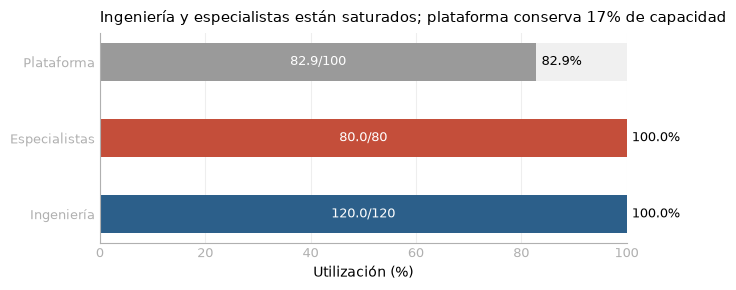


## Página 2 — ¿Dónde genera valor ampliar capacidad?

**Título:** Entre las ampliaciones de +10, especialistas aporta más; plataforma no agrega valor

**Insight:** +10 especialistas (+201 pts) supera a +10 ingeniería (+173 pts). +10 plataforma = 0. La combinación +10/+10 suma 374 pts (residual ≈ 0). Escenario ampliado: +749 pts vs base.


,Escenario,"Plan (A,P,D)",Objetivo,Δ vs base,% Δ,Restricciones activas
0,"Base (120,80,100)","(5.71, 11.43, 20.00)",3897.1,0.0,0.0,"Ingeniería, Especialistas, Demanda D"
1,"+10 Ingeniería (130,80,100)","(10.00, 10.00, 20.00)",4070.0,172.9,4.4,"Ingeniería, Especialistas, Demanda D"
2,"+10 Especialistas (120,90,100)","(2.86, 15.71, 20.00)",4098.6,201.4,5.2,"Ingeniería, Especialistas, Demanda D"
3,"+10 Plataforma (120,80,110)","(5.71, 11.43, 20.00)",3897.1,0.0,0.0,"Ingeniería, Especialistas, Demanda D"
4,"+10 Ing +10 Esp (130,90,100)","(7.14, 14.29, 20.00)",4271.4,374.3,9.6,"Ingeniería, Especialistas, Demanda D"
5,"Ampliado (140,100,120)","(8.57, 17.14, 20.00)",4645.7,748.6,19.2,"Ingeniería, Especialistas, Demanda D"


,Ampliación,Δ objetivo (pts)
0,+10 Ingeniería,172.9
1,+10 Especialistas,201.4
2,+10 Plataforma,0.0
3,+10 Ing +10 Esp,374.3
4,Interacción (residual),0.0


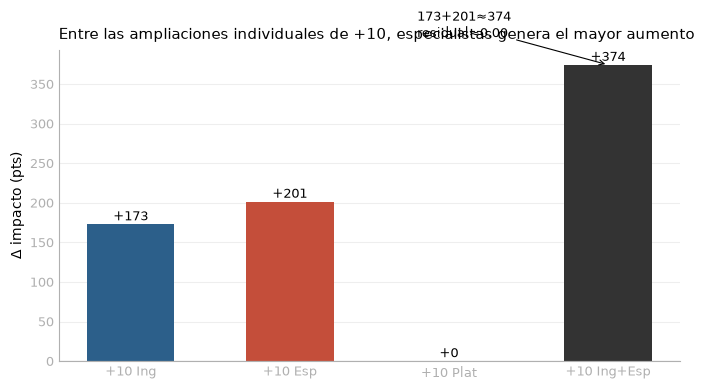


## Página 3 — ¿Conviene comprar capacidad al precio actual?

**Título:** La compra mejora el neto en ~168 pts tras descontar 480 pts de costo

**Insight:** El bruto sube ~648 pts pero la factura de capacidad (240 Ing + 240 Esp) deja un neto de 4 065 pts (+168 vs base). Precios actuales (12, 16) están por debajo de umbrales (~17.29, ~20.14).


,Escenario,Plan,e,s,Bruto,Costo,Neto
0,Sin compra,"(5.71, 11.43, 20.00)",0.0,0.0,3897.1,0.0,3897.1
1,Con compra,"(10.00, 15.00, 20.00)",20.0,15.0,4545.0,480.0,4065.0



**Referencia matemática (Pág. 3):** extensión del objetivo con $-12e - 16s$; capacidades $120+e$ y $80+s$.


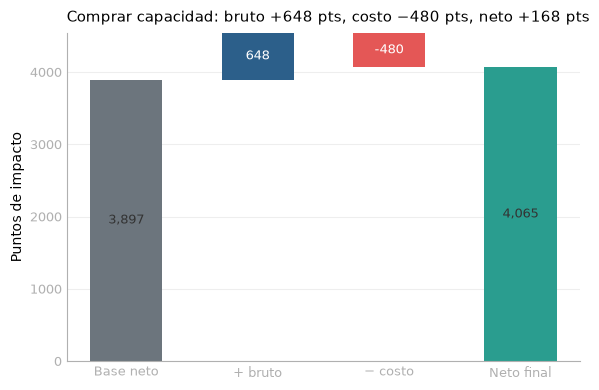

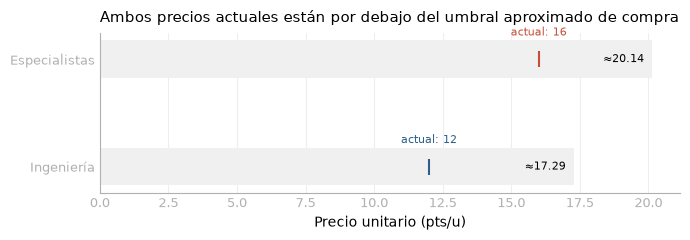


## Página 4 — ¿Cuánto cuesta comprometer un plan antes de conocer la capacidad?

**Título:** Robustez garantiza factibilidad con un costo de 8.9–10.0% vs reoptimización

**Plan robusto:** (4.29, 8.57, 20.00) · 3,522.86 pts


,Escenario,Capacidades,Plan robusto,Plan adaptado (ref.),Obj. robusto,Obj. adaptado (ref.),Brecha (pts),Brecha (%)
0,S1,"(120,80,100)","(4.29, 8.57, 20.00)","(5.71, 11.43, 20.00)",3522.9,3897.1,374.3,9.6
1,S2,"(110,90,95)","(4.29, 8.57, 20.00)","(0.00, 17.50, 18.75)",3522.9,3912.5,389.6,10.0
2,S3,"(130,70,105)","(4.29, 8.57, 20.00)","(12.86, 5.71, 20.00)",3522.9,3868.6,345.7,8.9



**Referencia matemática (Pág. 4):** el mismo $(A,P,D)$ debe satisfacer simultáneamente las tres familias de restricciones de recursos (nueve desigualdades).


,Escenario,Recurso,Capacidad,Uso,Holgura,Activa
0,S1,Ingeniería,120,110.0,10.0,No
1,S1,Especialistas,80,70.0,10.0,No
2,S1,Plataforma,100,77.1,22.9,No
3,S2,Ingeniería,110,110.0,0.0,Sí
4,S2,Especialistas,90,70.0,20.0,No
5,S2,Plataforma,95,77.1,17.9,No
6,S3,Ingeniería,130,110.0,20.0,No
7,S3,Especialistas,70,70.0,0.0,Sí
8,S3,Plataforma,105,77.1,27.9,No


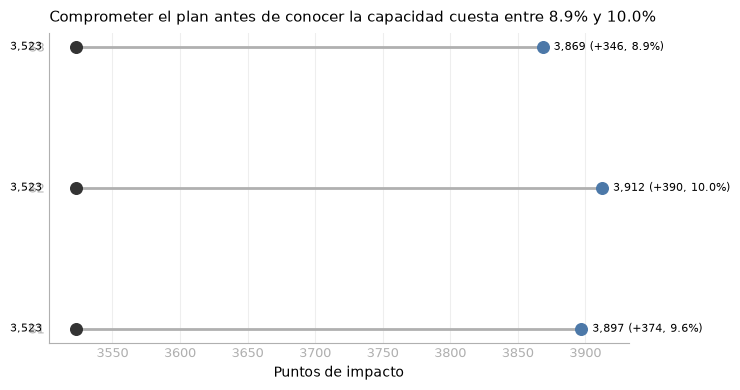

## Página 5 — ¿Qué aprendemos de los tres modelos?

,Problema de decisión,Resultado,Mecanismo,Límite
0,Reoptimización por escenario,+10 Esp (+201) > +10 Ing (+173); Plat = 0,Ing y Esp binding en base; holgura en plataforma,Aditividad probada solo en +10/+10 evaluado
1,Compra de capacidad,"Comprar e=20, s=15; neto +168 pts","Precios (12,16) < umbrales (~17.29, ~20.14)",Costos lineales; productividad homogénea
2,Compromiso robusto,"Plan (4,29; 8,57; 20); brecha 8.9–10.0%",S2 activa Ing; S3 activa Esp; Plat con holgura,Tres escenarios; sin adaptación ex post



**Conclusiones:**
1. Los cuellos de botella actuales son ingeniería y especialistas; ampliar plataforma no genera valor en el rango evaluado.
2. Conviene comprar capacidad al precio contractual: el neto mejora ~168 pts tras descontar 480 pts de costo.
3. Un plan único robusto sacrifica ~9–10% de impacto frente a reoptimizar con información perfecta.

**Supuestos a validar:** divisibilidad de paquetes; consumos lineales; impacto lineal y comparable; demandas estables; costos lineales de compra; igual productividad interna/externa; adecuación del conjunto de escenarios; imposibilidad de adaptar tras resolver incertidumbre.


**Tabla de supuestos críticos — Pág. 5**

,Modelo,Supuesto crítico,Consecuencia si es falso
0,Reoptimización (E1),El escenario se conoce antes de decidir,Los óptimos por escenario no serían implementa...
1,Compra de capacidad (E2),Capacidad divisible y precio lineal sin cargo ...,"La formulación LP debe cambiar, probablemente ..."
2,Compromiso robusto (E3),Solo tres escenarios modelados; plan no adapta...,El costo de robustez y la factibilidad cambian
3,Todos los modelos,Coeficientes de impacto y consumo lineales y e...,El LP puede no representar el desempeño operat...


**Manifiesto del informe**

,Página,Pregunta,Titular,Números clave,Figura,Tabla,Advertencia
0,1,¿Qué limita el plan óptimo?,Ing y Esp saturados; plataforma con holgura,"Plan (5.71, 11.43, 20.00) · 3,897 pts",01_base_utilization.svg,01_base_summary.csv,Precios sombra son locales
1,2,¿Dónde genera valor ampliar capacidad?,Especialistas +10 aporta más; plataforma 0,+173 / +201 / 0 / +374 (residual≈0),02_capacity_value.svg,02_scenarios.csv,Aditividad solo en +10/+10 evaluado
2,3,¿Conviene comprar capacidad?,Neto +168 pts tras costo 480,3897 → 4545 → −480 → 4065,03_capacity_purchase_waterfall.svg,03_purchase_summary.csv,Costos lineales; compra continua
3,4,¿Cuánto cuesta el compromiso robusto?,Brecha 8.9–10.0% vs referencia,"Robusto 3,523 pts",04_robust_gap.svg,04_robust_summary.csv,Planes adaptados no implementables hoy
4,5,¿Qué aprendemos?,Síntesis de tres modelos,Ver tabla síntesis,—,05_synthesis.csv,Ver supuestos listados


✓ Assets y CSV exportados en /home/lorenn/Desktop/Universidad/inv-operativa-26/clase 4/report_assets


In [9]:
# =============================================================================
# PÁGINA 1
# =============================================================================
display(Markdown("""
## Página 1 — ¿Qué limita actualmente el plan óptimo?

**Título:** Ingeniería y especialistas saturados; plataforma con capacidad disponible

**Insight:** El plan óptimo base agota ingeniería (100%) y especialistas (100%). Plataforma opera al 82,9% con holgura de 17,1 unidades. Despliegue dedicado (D) alcanza su límite de demanda (20).
"""))

tabla_p1 = pd.DataFrame([
    {"Concepto": "Plan óptimo", "Valor": fmt_plan(res_base.A, res_base.P, res_base.D)},
    {"Concepto": "Objetivo (pts)", "Valor": f"{res_base.objetivo:,.2f}"},
    {"Concepto": "Precio sombra Ing (local)", "Valor": f"{res_base.precio_ing:.2f}"},
    {"Concepto": "Precio sombra Esp (local)", "Valor": f"{res_base.precio_esp:.2f}"},
])
display(tabla_util.round(1))
display(tabla_p1)

display(Markdown("""
**Referencia matemática (Pág. 1):**

$$\max Z = 72A + 95P + 120D$$

sujeto a $3A+2P+4D \le 120$, $A+3P+2D \le 80$, $2A+P+3D \le 100$ y límites de demanda.
"""))

# Variables locales para figura de informe (evitar colisiones con celdas suplementarias)
labels_p2 = ["+10 Ing", "+10 Esp", "+10 Plat", "+10 Ing+Esp"]
deltas_p2 = [delta_I, delta_E, delta_P, delta_IE]
cols_p2 = [COL_RECURSO["Ingeniería"], COL_RECURSO["Especialistas"], COL_RECURSO["Plataforma"], COL_DECISION["neutral"]]
recursos_p1 = ["Ingeniería", "Especialistas", "Plataforma"]
utils_p1 = [100 * res_base.uso_ing / res_base.ing_cap,
            100 * res_base.uso_esp / res_base.esp_cap,
            100 * res_base.uso_pla / res_base.plat_cap]

fig1, ax1 = plt.subplots(figsize=(7, 3))
for i, (r, u) in enumerate(zip(recursos_p1, utils_p1)):
    ax1.barh(i, u, color=COL_RECURSO[r], height=0.5)
    ax1.barh(i, 100 - u, left=u, color="#F0F0F0", height=0.5)
    row = tabla_util.iloc[i]
    ax1.text(u / 2, i, f"{row['Uso']:.1f}/{row['Capacidad']:.0f}", ha="center", va="center", fontsize=9, color="white")
    ax1.text(u + 1, i, f"{u:.1f}%", va="center", fontsize=9)
ax1.set_xlim(0, 100)
ax1.set_yticks(range(3))
ax1.set_yticklabels(recursos_p1)
ax1.set_xlabel("Utilización (%)")
ax1.set_title("Ingeniería y especialistas están saturados; plataforma conserva 17% de capacidad", loc="left", pad=8)
apply_style(ax1, grid="x")
fig1.tight_layout()
export_fig(fig1, "01_base_utilization")
plt.show()

# =============================================================================
# PÁGINA 2
# =============================================================================
display(Markdown("""
## Página 2 — ¿Dónde genera valor ampliar capacidad?

**Título:** Entre las ampliaciones de +10, especialistas aporta más; plataforma no agrega valor

**Insight:** +10 especialistas (+201 pts) supera a +10 ingeniería (+173 pts). +10 plataforma = 0. La combinación +10/+10 suma 374 pts (residual ≈ 0). Escenario ampliado: +749 pts vs base.
"""))
display(df_esc_decision.round(1))
display(tabla_inter.round(1))

fig2, ax2 = plt.subplots(figsize=(7, 4))
ax2.bar(labels_p2, deltas_p2, color=cols_p2, width=0.55)
ax2.axhline(0, color=COL_DECISION["contexto"], lw=0.8)
for i, d in enumerate(deltas_p2):
    ax2.text(i, d + 5, f"+{d:.0f}", ha="center", fontsize=9)
ax2.annotate(f"{delta_I:.0f}+{delta_E:.0f}≈{delta_IE:.0f}\nresidual≈{interaccion:.2f}",
             xy=(3, delta_IE), xytext=(1.8, delta_IE + 35), fontsize=9,
             arrowprops=dict(arrowstyle="->", lw=0.8))
ax2.set_ylabel("Δ impacto (pts)")
ax2.set_title("Entre las ampliaciones individuales de +10, especialistas genera el mayor aumento", loc="left", pad=8)
apply_style(ax2)
fig2.tight_layout()
export_fig(fig2, "02_capacity_value")
plt.show()

# =============================================================================
# PÁGINA 3
# =============================================================================
display(Markdown(f"""
## Página 3 — ¿Conviene comprar capacidad al precio actual?

**Título:** La compra mejora el neto en ~{incremental:.0f} pts tras descontar 480 pts de costo

**Insight:** El bruto sube ~648 pts pero la factura de capacidad (240 Ing + 240 Esp) deja un neto de 4 065 pts (+{incremental:.0f} vs base). Precios actuales (12, 16) están por debajo de umbrales (~{umbral_e:.2f}, ~{umbral_s:.2f}).
"""))
display(tabla_compra.round(1))

display(Markdown("""
**Referencia matemática (Pág. 3):** extensión del objetivo con $-12e - 16s$; capacidades $120+e$ y $80+s$.
"""))

fig3, ax3 = plt.subplots(figsize=(6, 4))
steps = [
    (z_base, 0, COL_DECISION["base"], z_base),
    (res_compra.bruto - z_base, z_base, COL_RECURSO["Ingeniería"], res_compra.bruto - z_base),
    (-res_compra.costo_total, res_compra.neto + res_compra.costo_total, COL_DECISION["negativo"], -res_compra.costo_total),
    (res_compra.neto, 0, COL_DECISION["positivo"], res_compra.neto),
]
for i, (h, b, col, lbl) in enumerate(steps):
    ax3.bar(i, h, bottom=b if i in (1, 2) else 0, color=col, width=0.55)
    ax3.text(i, (b + h/2) if i in (1,2) else h/2, f"{lbl:,.0f}", ha="center", va="center", fontsize=9,
             color="white" if i in (1,2) else COL_DECISION["neutral"])
ax3.set_xticks(range(4))
ax3.set_xticklabels(["Base neto", "+ bruto", "− costo", "Neto final"])
ax3.set_ylabel("Puntos de impacto")
ax3.set_title(f"Comprar capacidad: bruto +648 pts, costo −480 pts, neto +{incremental:.0f} pts", loc="left", pad=8)
apply_style(ax3)
fig3.tight_layout()
export_fig(fig3, "03_capacity_purchase_waterfall")
plt.show()

# Umbral bullet chart
fig3b, ax3b = plt.subplots(figsize=(7, 2.5))
for i, (nombre, precio_act, umbral, col) in enumerate([
    ("Ingeniería", COSTO_E_BASE, umbral_e, COL_RECURSO["Ingeniería"]),
    ("Especialistas", COSTO_S_BASE, umbral_s, COL_RECURSO["Especialistas"]),
]):
    ax3b.barh(i, umbral, color="#F0F0F0", height=0.35)
    ax3b.scatter([precio_act], [i], color=col, s=120, zorder=5, marker="|")
    ax3b.text(precio_act, i + 0.22, f"actual: {precio_act}", ha="center", fontsize=8, color=col)
    ax3b.text(umbral - 0.3, i, f"≈{umbral:.2f}", ha="right", va="center", fontsize=8)
ax3b.set_yticks([0, 1])
ax3b.set_yticklabels(["Ingeniería", "Especialistas"])
ax3b.set_xlabel("Precio unitario (pts/u)")
ax3b.set_title("Ambos precios actuales están por debajo del umbral aproximado de compra", loc="left", pad=8)
apply_style(ax3b, grid="x")
fig3b.tight_layout()
export_fig(fig3b, "03_purchase_thresholds")
plt.show()

# =============================================================================
# PÁGINA 4
# =============================================================================
display(Markdown(f"""
## Página 4 — ¿Cuánto cuesta comprometer un plan antes de conocer la capacidad?

**Título:** Robustez garantiza factibilidad con un costo de {gap_min:.1f}–{gap_max:.1f}% vs reoptimización

**Plan robusto:** {fmt_plan(res_robusto.A, res_robusto.P, res_robusto.D)} · {res_robusto.objetivo:,.2f} pts
"""))
display(df_robusto.round(1))

display(Markdown("""
**Referencia matemática (Pág. 4):** el mismo $(A,P,D)$ debe satisfacer simultáneamente las tres familias de restricciones de recursos (nueve desigualdades).
"""))
display(df_val_rob.round(1))

fig4, ax4 = plt.subplots(figsize=(7.5, 4))
for i, row in df_robusto.iterrows():
    r, a = row["Obj. robusto"], row["Obj. adaptado (ref.)"]
    ax4.plot([r, a], [i, i], color=COL_DECISION["contexto"], lw=2)
    ax4.scatter([r], [i], color=COL_DECISION["robusto"], s=70, zorder=3)
    ax4.scatter([a], [i], color=COL_DECISION["referencia"], s=70, zorder=3)
    ax4.text(r - 25, i, f"{r:,.0f}", ha="right", va="center", fontsize=8)
    ax4.text(a + 8, i, f"{a:,.0f} (+{row['Brecha (pts)']:.0f}, {row['Brecha (%)']:.1f}%)", va="center", fontsize=8)
ax4.set_yticks(range(len(df_robusto)))
ax4.set_yticklabels(df_robusto["Escenario"])
ax4.set_xlabel("Puntos de impacto")
ax4.set_title(f"Comprometer el plan antes de conocer la capacidad cuesta entre {gap_min:.1f}% y {gap_max:.1f}%", loc="left", pad=8)
apply_style(ax4, grid="x")
fig4.tight_layout()
export_fig(fig4, "04_robust_gap")
plt.show()

# =============================================================================
# PÁGINA 5
# =============================================================================
tabla_sintesis = pd.DataFrame([
    {"Problema de decisión": "Reoptimización por escenario",
     "Resultado": f"+10 Esp (+{delta_E:.0f}) > +10 Ing (+{delta_I:.0f}); Plat = 0",
     "Mecanismo": "Ing y Esp binding en base; holgura en plataforma",
     "Límite": "Aditividad probada solo en +10/+10 evaluado"},
    {"Problema de decisión": "Compra de capacidad",
     "Resultado": f"Comprar e=20, s=15; neto +{incremental:.0f} pts",
     "Mecanismo": f"Precios (12,16) < umbrales (~{umbral_e:.2f}, ~{umbral_s:.2f})",
     "Límite": "Costos lineales; productividad homogénea"},
    {"Problema de decisión": "Compromiso robusto",
     "Resultado": f"Plan (4,29; 8,57; 20); brecha {gap_min:.1f}–{gap_max:.1f}%",
     "Mecanismo": "S2 activa Ing; S3 activa Esp; Plat con holgura",
     "Límite": "Tres escenarios; sin adaptación ex post"},
])
display(Markdown("## Página 5 — ¿Qué aprendemos de los tres modelos?"))
display(tabla_sintesis)

display(Markdown("""
**Conclusiones:**
1. Los cuellos de botella actuales son ingeniería y especialistas; ampliar plataforma no genera valor en el rango evaluado.
2. Conviene comprar capacidad al precio contractual: el neto mejora ~168 pts tras descontar 480 pts de costo.
3. Un plan único robusto sacrifica ~9–10% de impacto frente a reoptimizar con información perfecta.

**Supuestos a validar:** divisibilidad de paquetes; consumos lineales; impacto lineal y comparable; demandas estables; costos lineales de compra; igual productividad interna/externa; adecuación del conjunto de escenarios; imposibilidad de adaptar tras resolver incertidumbre.
"""))

# --- Export CSV ---
tabla_util.round(2).to_csv(REPORT_ASSETS / "01_base_summary.csv", index=False)
df_esc_decision.round(2).to_csv(REPORT_ASSETS / "02_scenarios.csv", index=False)
tabla_compra.round(2).to_csv(REPORT_ASSETS / "03_purchase_summary.csv", index=False)
df_robusto.round(2).to_csv(REPORT_ASSETS / "04_robust_summary.csv", index=False)
tabla_sintesis.to_csv(REPORT_ASSETS / "05_synthesis.csv", index=False)


# Tabla de supuestos críticos para Figma (Pág. 5)
tabla_supuestos_figma = pd.DataFrame([
    {"Modelo": "Reoptimización (E1)", "Supuesto crítico": "El escenario se conoce antes de decidir",
     "Consecuencia si es falso": "Los óptimos por escenario no serían implementables"},
    {"Modelo": "Compra de capacidad (E2)", "Supuesto crítico": "Capacidad divisible y precio lineal sin cargo fijo/bloques",
     "Consecuencia si es falso": "La formulación LP debe cambiar, probablemente a MILP"},
    {"Modelo": "Compromiso robusto (E3)", "Supuesto crítico": "Solo tres escenarios modelados; plan no adaptable ex post",
     "Consecuencia si es falso": "El costo de robustez y la factibilidad cambian"},
    {"Modelo": "Todos los modelos", "Supuesto crítico": "Coeficientes de impacto y consumo lineales y estables",
     "Consecuencia si es falso": "El LP puede no representar el desempeño operativo real"},
])
display(Markdown("**Tabla de supuestos críticos — Pág. 5**"))
display(tabla_supuestos_figma)
tabla_supuestos_figma.to_csv(REPORT_ASSETS / "05_assumptions_figma.csv", index=False)

# --- Manifest ---
manifest = pd.DataFrame([
    {"Página": 1, "Pregunta": "¿Qué limita el plan óptimo?",
     "Titular": "Ing y Esp saturados; plataforma con holgura",
     "Números clave": f"Plan {fmt_plan(res_base.A,res_base.P,res_base.D)} · {res_base.objetivo:,.0f} pts",
     "Figura": "01_base_utilization.svg", "Tabla": "01_base_summary.csv",
     "Advertencia": "Precios sombra son locales"},
    {"Página": 2, "Pregunta": "¿Dónde genera valor ampliar capacidad?",
     "Titular": "Especialistas +10 aporta más; plataforma 0",
     "Números clave": f"+173 / +201 / 0 / +374 (residual≈0)",
     "Figura": "02_capacity_value.svg", "Tabla": "02_scenarios.csv",
     "Advertencia": "Aditividad solo en +10/+10 evaluado"},
    {"Página": 3, "Pregunta": "¿Conviene comprar capacidad?",
     "Titular": f"Neto +{incremental:.0f} pts tras costo 480",
     "Números clave": "3897 → 4545 → −480 → 4065",
     "Figura": "03_capacity_purchase_waterfall.svg", "Tabla": "03_purchase_summary.csv",
     "Advertencia": "Costos lineales; compra continua"},
    {"Página": 4, "Pregunta": "¿Cuánto cuesta el compromiso robusto?",
     "Titular": f"Brecha {gap_min:.1f}–{gap_max:.1f}% vs referencia",
     "Números clave": f"Robusto {res_robusto.objetivo:,.0f} pts",
     "Figura": "04_robust_gap.svg", "Tabla": "04_robust_summary.csv",
     "Advertencia": "Planes adaptados no implementables hoy"},
    {"Página": 5, "Pregunta": "¿Qué aprendemos?",
     "Titular": "Síntesis de tres modelos",
     "Números clave": "Ver tabla síntesis",
     "Figura": "—", "Tabla": "05_synthesis.csv",
     "Advertencia": "Ver supuestos listados"},
])
display(Markdown("**Manifiesto del informe**"))
display(manifest)
manifest.to_csv(REPORT_ASSETS / "00_manifest.csv", index=False)
print(f"✓ Assets y CSV exportados en {REPORT_ASSETS.resolve()}")


In [10]:
# =============================================================================
# Suite QA final
# =============================================================================
qa_errors = []

def check(cond, msg):
    if not cond:
        qa_errors.append(msg)

# Base
check(res_base.status == "OPTIMAL", "Base no óptimo")
check(validar_lp(res_base)["ok"], "Validación base fallida")
check(abs(res_base.objetivo - 3897.1429) < 0.01, "Objetivo base fuera de rango")
check(abs(res_base.holgura_pla - 17.1429) < 0.01, "Holgura plataforma base")

# E1
for n, r in resultados_e1.items():
    check(r is not None, f"{n} no óptimo")
    check(validar_lp(r)["ok"], f"{n} validación fallida")
check(abs(interaccion) < 0.01, "Interacción no nula")
check(len(df_mono) > 0 and df_mono["OK"].all(), "Monotonicidad fallida")

# E2
check(validar_compra(res_compra, COSTO_E_BASE, COSTO_S_BASE)["ok"], "Compra validación")
check(abs(res_compra.neto - 4065) < 0.01, "Neto compra fuera de rango")
check(res_sin.e < TOL and res_sin.s < TOL, "Costos altos no anulan compra")
check(abs(res_sin.A - res_base.A) < 1e-3, "Costos altos no reproducen plan base")
check(umbral_e is not None and umbral_s is not None, "Umbrales no calculados")
check(abs(umbral_e - 17.29) < 0.05, f"Umbral Ing {umbral_e}")
check(abs(umbral_s - 20.14) < 0.05, f"Umbral Esp {umbral_s}")


# E1 — Control 2: ampliación solo plataforma
r_plat = resultados_e1["+10 Plataforma (120,80,110)"]
check(abs(r_plat.objetivo - z_base) < 0.01, "Control E1: +10 Plat debe mantener objetivo base")
check(r_plat.A <= res_base.A + TOL and r_plat.P <= res_base.P + TOL and r_plat.D <= res_base.D + TOL,
      "Control E1: solución base factible en +10 Plat")

# E3 — Control 1: plan cero factible en todos los escenarios
for nombre, caps in ESCENARIOS_E3.items():
    ok_cero = (0 <= caps["ing_cap"] + TOL and 0 <= caps["esp_cap"] + TOL and 0 <= caps["plat_cap"] + TOL)
    check(ok_cero, f"Control E3: (0,0,0) infactible en {nombre}")

# E3
check(res_robusto.status == "OPTIMAL", "Robusto no óptimo")
check(abs(res_robusto.objetivo - 3522.86) < 0.01, "Objetivo robusto fuera de rango")
check((df_val_rob["Holgura"] >= -TOL).all(), "Robusto infactible")
s2_ing = df_val_rob[(df_val_rob["Escenario"] == "S2") & (df_val_rob["Recurso"] == "Ingeniería")]["Activa"].iloc[0]
s3_esp = df_val_rob[(df_val_rob["Escenario"] == "S3") & (df_val_rob["Recurso"] == "Especialistas")]["Activa"].iloc[0]
check(s2_ing == "Sí", "S2 Ing no activa")
check(s3_esp == "Sí", "S3 Esp no activa")
plat_holg = df_val_rob[df_val_rob["Recurso"] == "Plataforma"]["Holgura"]
check((plat_holg > 0).all(), "Plataforma no tiene holgura positiva")

if qa_errors:
    print("✗ QA FALLIDO:")
    for e in qa_errors:
        print(f"  - {e}")
    raise AssertionError(f"{len(qa_errors)} checks fallidos")
else:
    print("✓ ALL ANALYTICAL AND REPORT QA CHECKS PASSED")


✓ ALL ANALYTICAL AND REPORT QA CHECKS PASSED


In [11]:
# Trazabilidad del taller (estructuras formales — completar campos humanos)
import json

TRACEABILITY = {
    "C04E1": {
        "exercise_id": "C04E1",
        "model_version": "reoptimizacion_por_escenario_v1",
        "prompt_hash": "[COMPLETAR POR EL EQUIPO]",
        "agent": "[COMPLETAR POR EL EQUIPO]",
        "accepted_changes": [],
        "rejected_changes": [],
        "tests": [
            "reconstruccion_objetivo_base",
            "factibilidad_seis_escenarios",
            "monotonicidad_pares_validos",
            "residual_interaccion_+10_+10",
        ],
        "team_interpretation": "[COMPLETAR POR EL EQUIPO]",
    },
    "C04E2": {
        "exercise_id": "C04E2",
        "model_version": "compra_endogena_capacidad_v1",
        "prompt_hash": "[COMPLETAR POR EL EQUIPO]",
        "agent": "[COMPLETAR POR EL EQUIPO]",
        "accepted_changes": [],
        "rejected_changes": [],
        "tests": [
            "reconstruccion_bruto_costo_neto",
            "control_sin_compra_e_s_0",
            "control_costo_prohibitivo",
            "umbral_compra_reoptimizacion",
        ],
        "team_interpretation": "[COMPLETAR POR EL EQUIPO]",
    },
    "C04E3": {
        "exercise_id": "C04E3",
        "model_version": "plan_robusto_interseccion_v1",
        "prompt_hash": "[COMPLETAR POR EL EQUIPO]",
        "agent": "[COMPLETAR POR EL EQUIPO]",
        "accepted_changes": [],
        "rejected_changes": [],
        "tests": [
            "control_plan_cero_factible",
            "nueve_restricciones_factibles",
            "S2_ingenieria_activa",
            "S3_especialistas_activa",
            "plataforma_holgura_positiva",
        ],
        "team_interpretation": "[COMPLETAR POR EL EQUIPO]",
    },
}

for ex_id, payload in TRACEABILITY.items():
    print(f"\n--- {ex_id} ---")
    print(json.dumps(payload, indent=2, ensure_ascii=False))



--- C04E1 ---
{
  "exercise_id": "C04E1",
  "model_version": "reoptimizacion_por_escenario_v1",
  "prompt_hash": "[COMPLETAR POR EL EQUIPO]",
  "agent": "[COMPLETAR POR EL EQUIPO]",
  "accepted_changes": [],
  "rejected_changes": [],
  "tests": [
    "reconstruccion_objetivo_base",
    "factibilidad_seis_escenarios",
    "monotonicidad_pares_validos",
    "residual_interaccion_+10_+10"
  ],
  "team_interpretation": "[COMPLETAR POR EL EQUIPO]"
}

--- C04E2 ---
{
  "exercise_id": "C04E2",
  "model_version": "compra_endogena_capacidad_v1",
  "prompt_hash": "[COMPLETAR POR EL EQUIPO]",
  "agent": "[COMPLETAR POR EL EQUIPO]",
  "accepted_changes": [],
  "rejected_changes": [],
  "tests": [
    "reconstruccion_bruto_costo_neto",
    "control_sin_compra_e_s_0",
    "control_costo_prohibitivo",
    "umbral_compra_reoptimizacion"
  ],
  "team_interpretation": "[COMPLETAR POR EL EQUIPO]"
}

--- C04E3 ---
{
  "exercise_id": "C04E3",
  "model_version": "plan_robusto_interseccion_v1",
  "prompt_ha

## Ticket de salida — completar por el equipo

### 1. Decisión que podemos defender

`[COMPLETAR POR EL EQUIPO]`

**Evidencia disponible:** resultados base, seis escenarios, compra endógena y plan robusto resumidos en *Material para informe profesional*; formulaciones y FMA por ejercicio.

### 2. Control que evitó un error

`[COMPLETAR POR EL EQUIPO]`

**Controles disponibles:** reconstrucción del objetivo; factibilidad de recursos y demandas; monotonicidad (E1); replicación sin compra y test de costo prohibitivo (E2); plan cero factible y verificación de nueve restricciones (E3); suite QA final.

### 3. Supuesto que debería validar un responsable real

`[COMPLETAR POR EL EQUIPO]`

**Supuestos candidatos documentados:** linealidad; divisibilidad; estructura contractual de compra; completitud del conjunto de escenarios; imposibilidad de adaptar el plan tras resolver la incertidumbre.


# Cobertura frente a instrucciones originales

| Requisito | E1 | E2 | E3 |
|-----------|:--:|:--:|:--:|
| Pregunta de decisión representada | ✓ | ✓ | ✓ |
| Formulación primal completa | ✓ | ✓ | ✓ |
| Variables / dominios | ✓ | ✓ | ✓ |
| Función objetivo | ✓ | ✓ | ✓ |
| Restricciones nombradas / interpretadas | ✓ | ✓ | ✓ |
| Supuestos y exclusiones | ✓ | ✓ | ✓ |
| FMA | ✓ | ✓ | ✓ |
| Dos controles / casos manuales | ✓ | ✓ | ✓ |
| Implementación con solver | ✓ | ✓ | ✓ |
| Verificación independiente | ✓ | ✓ | ✓ |
| Comparación requerida | ✓ | ✓ | ✓ |
| Sección de trazabilidad de proceso | ✓ | ✓ | ✓ |

**Nota:** Los ítems de trazabilidad humana (hash de prompt, agente, cambios aceptados/rechazados, interpretación del equipo, firmas) quedan marcados `[COMPLETAR POR EL EQUIPO]` sin fabricar proveniencia.
